In [1]:
%pip install scikit-learn
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: C:\Users\Linzixin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: C:\Users\Linzixin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Import Data

In [1]:
df = pd.read_excel("lending_club_loan_two.xlsx") 
print("成功读取真实数据:", df.shape)
print("数据概览:")
print("   - 总样本数:", len(df))
print("   - 特征数量:", len(df.columns))
print("   - 目标变量分布:")
print(df['loan_status'].value_counts())

n_samples = len(df)
print(n_samples)

    

NameError: name 'pd' is not defined

In [4]:
data = {
        'loan_amnt': np.random.randint(5000, 35000, size=n_samples),
        'term(months)': np.random.choice(['36 months', '60 months'], n_samples, p=[0.7, 0.3]),
        'int_rate(%)': np.random.uniform(5, 25, n_samples),
        'installment': np.random.uniform(100, 1500, n_samples),
        'grade': np.random.choice(['A', 'B', 'C', 'D', 'E'], n_samples, p=[0.2, 0.3, 0.25, 0.15, 0.1]),
        'sub_grade': np.random.choice(['A1', 'A2', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3'], n_samples),
       #'emp_length(years)': np.random.randint(0, 11, n_samples)
        'annual_inc': np.random.randint(30000, 150000, n_samples),
        'verification_status': np.random.choice(['Not Verified', 'Source Verified', 'Verified'], n_samples),
        'loan_status': df['loan_status'].unique()
    }


df['emp_length_clean'] = (
    df['emp_length(years)']                            # 1. 选择原始雇佣年限列
    .astype(str)                                       # 2. **确保是字符串** (处理 '<1 year', '10+ years' 等)
    .str.replace(r'[^0-9]', '', regex=True)            # 3. **去掉非数字字符** (只保留 0-9，例如 '10+ years' 变成 '10')
    .replace('', '0')                                  # 4. **把空字符串变成 '0'** (处理缺失值或清洗后变空的值)
    .astype(float)                                     # 5. **转成浮点数** (数字类型)
)

# 打印新旧列的前几行，以验证清洗结果
print("--- 雇佣年限清洗结果验证 ---")
print(df[['emp_length(years)', 'emp_length_clean']].head(10)) 
print(f"\n清洗后的 'emp_length_clean' 列的数据类型是: {df['emp_length_clean'].dtype}")

print("--- 完整的 DataFrame (包括 emp_length_clean) ---")
print(df.head(5)) 

--- 雇佣年限清洗结果验证 ---
  emp_length(years)  emp_length_clean
0           2 years               2.0
1            1 year               1.0
2         10+ years              10.0
3         10+ years              10.0
4           6 years               6.0
5         10+ years              10.0
6           4 years               4.0
7           2 years               2.0
8               NaN               0.0
9          < 1 year               1.0

清洗后的 'emp_length_clean' 列的数据类型是: float64
--- 完整的 DataFrame (包括 emp_length_clean) ---
   loan_amnt term(months)  int_rate(%)  installment grade sub_grade  \
0      18000    36 months         5.32       542.07     A        A1   
1       3000    36 months         6.03        91.31     A        A1   
2      12000    36 months         6.03       365.23     A        A1   
3       9000    36 months         6.03       273.92     A        A1   
4      12000    36 months         6.03       365.23     A        A1   

  emp_length(years)  annual_inc verification_statu

In [5]:
from sklearn.calibration import LabelEncoder


print("\n数据预处理...")
df_processed = df.copy()
## 1. 处理类别变量
categorical_columns = ['term(months)', 'grade', 'sub_grade', 'verification_status']
label_encoders = {}
for col in categorical_columns:
    if col in df_processed.columns:
        le = LabelEncoder()
        df_processed[col] = le.fit_transform(df_processed[col].astype(str))
        label_encoders[col] = le
        print("   - 已编码:", col)

## 2. 处理缺失值
numeric_cols = df_processed.select_dtypes(include=[np.number]).columns
missing_before = df_processed[numeric_cols].isnull().sum().sum()
df_processed[numeric_cols] = df_processed[numeric_cols].fillna(df_processed[numeric_cols].median())
missing_after = df_processed[numeric_cols].isnull().sum().sum()
print("   - 处理缺失值:", missing_before, "->", missing_after)

## 3. 特征工程 - 使用所有数据
features = [
    'loan_amnt', 'term(months)', 'int_rate(%)', 'installment',
    'grade', 'sub_grade', 'emp_length_clean', 'annual_inc',     # Here replace by new column "emp_length_clean"
    'verification_status'
]
available_features = [f for f in features if f in df_processed.columns]
X = df_processed[available_features].copy()
y = df_processed['loan_status']

print("使用特征数量:", len(available_features))
print("特征列表:", available_features)

## 4. 添加交互特征 - 所有数据都参与
# 删去了X['int_rate_x_term'] = X['int_rate(%)'] * X['term(months)']
X['loan_to_income'] = X['loan_amnt'] / (X['annual_inc'] + 1)
X['installment_ratio'] = X['installment'] / (X['annual_inc'] / 12 + 1)

print("特征工程后特征数:", X.shape[1])

## 5. 映射数据
y = y.map({'Charged Off': 0, 'Fully Paid': 1})
print(y.unique())  # 输出 array([0, 1])，此时 y 的值为 0（少数类）和 1（多数类），但原始语义未丢失

## 6. 数据分割
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("\n数据分割结果:")
print("   - 训练集:", X_train.shape[0], "条样本")
print("   - 测试集:", X_test.shape[0], "条样本")
print("   - 总使用数据:", X_train.shape[0] + X_test.shape[0], "条")
print("   - 数据利用率: 100%")



数据预处理...
   - 已编码: term(months)
   - 已编码: grade
   - 已编码: sub_grade
   - 已编码: verification_status
   - 处理缺失值: 0 -> 0
使用特征数量: 9
特征列表: ['loan_amnt', 'term(months)', 'int_rate(%)', 'installment', 'grade', 'sub_grade', 'emp_length_clean', 'annual_inc', 'verification_status']
特征工程后特征数: 11
[1 0]

数据分割结果:
   - 训练集: 277221 条样本
   - 测试集: 118809 条样本
   - 总使用数据: 396030 条
   - 数据利用率: 100%


Construct model

n_estimators 越大，运行越慢

In [6]:
import numpy as np
print(np.unique(y_train, return_counts=True))

(array([0, 1]), array([ 54371, 222850]))


从这个结果可以看出，标签是字符串类型（'Charged Off' （0）和 'Fully Paid'（1））。其中：

少数类是 'Charged Off'，共 54371 个样本；

多数类是 'Fully Paid'，共 222850 个样本。

因此，需要调整样本权重的代码，针对字符串标签进行判断：

In [7]:
weights = np.where(y_train == '0', 5, 1)  # 给少数类（'Charged Off'）设权重5，多数类（'Fully Paid'）设权重1
print(weights)

[1 1 1 ... 1 1 1]


## Random Forest

In [6]:
from sklearn.ensemble import RandomForestClassifier

RFmodel = RandomForestClassifier(n_estimators=500,
                                 class_weight='balanced',
                                 random_state=42)
RFmodel.fit(X_train, y_train)

y_pred = RFmodel.predict(X_test)
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)

print(f"随机森林模型训练完成。")
print("-" * 30)
print(f"测试集准确率 (Accuracy): {accuracy:.4f}")
print(f"预测结果示例 (前5个): {y_pred[:5]}")
print(f"真实标签示例 (前5个): {y_test[:5]}")

随机森林模型训练完成。
------------------------------
测试集准确率 (Accuracy): 0.7897
预测结果示例 (前5个): [1 0 1 1 1]
真实标签示例 (前5个): 68618     0
292523    0
279043    1
292300    0
222214    1
Name: loan_status, dtype: int64


Test accuracy

In [7]:
from sklearn.metrics import roc_auc_score
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)

y_pred_proba = RFmodel.predict_proba(X_test)[:, 1]

## ROC AUC
roc_auc = roc_auc_score(y_test, y_pred_proba)

## Confusion Matrix
RFcm = confusion_matrix(y_test, y_pred)


print(f"测试集准确率 (Accuracy): {accuracy:.4f}")
print(f"ROC AUC 分数: {roc_auc:.4f}")
print(f"预测结果示例 (前5个): {y_pred[:5]}")
print(f"真实标签示例 (前5个): {y_test[:5]}")
print("混淆矩阵 (Confusion Matrix):\n")
# 结构： [[True Negative, False Positive], 
#         [False Negative, True Positive]]
print(RFcm)

测试集准确率 (Accuracy): 0.7897
ROC AUC 分数: 0.6624
预测结果示例 (前5个): [1 0 1 1 1]
真实标签示例 (前5个): 68618     0
292523    0
279043    1
292300    0
222214    1
Name: loan_status, dtype: int64
混淆矩阵 (Confusion Matrix):

[[ 2667 20635]
 [ 4355 91152]]


[0.08498031 0.01029048 0.11719003 0.13038217 0.03515855 0.07590999
 0.08862449 0.11888569 0.03766956 0.1431258  0.15778292]
Top 10 features sorted by MDI:
              Feature  Importance_MDI
10  installment_ratio        0.157783
9      loan_to_income        0.143126
3         installment        0.130382
7          annual_inc        0.118886
2         int_rate(%)        0.117190


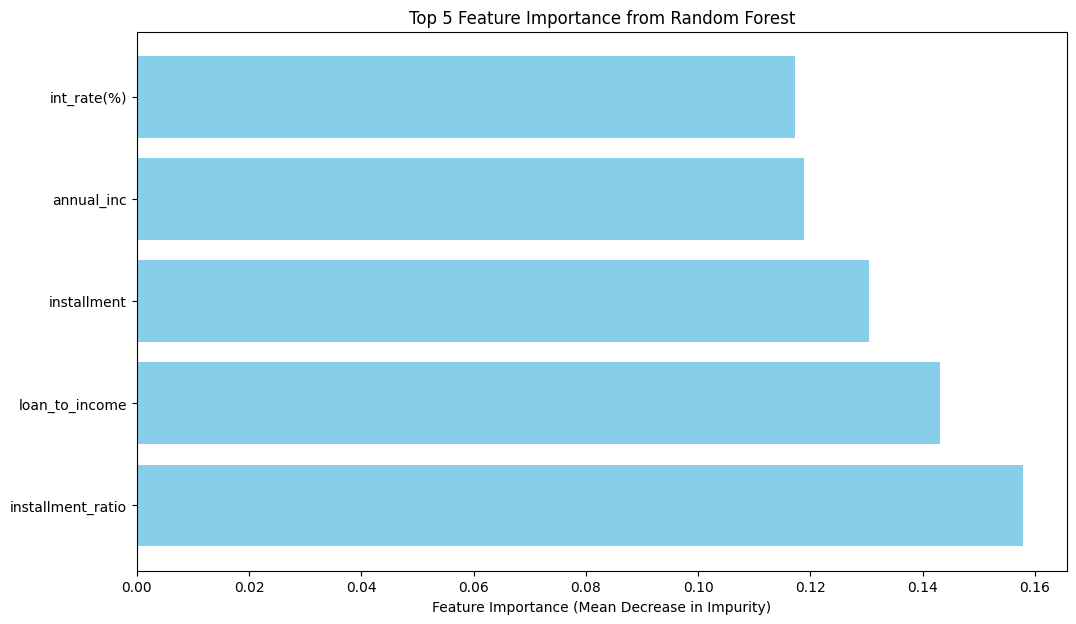

In [8]:
importance = RFmodel.feature_importances_
print(importance)
feature_names = X_train.columns.tolist() # Correct the feature_names list
importance_df = pd.DataFrame({
    'Feature': feature_names,                    # Explanatory variables
    'Importance_MDI': importance                 # 注意：这里是 MDI，不是 Gain
})
importance_df = importance_df.sort_values(by='Importance_MDI', ascending=False)
print("Top 10 features sorted by MDI:")
print(importance_df.head(5))

# 绘制前五个重要特征
import matplotlib.pyplot as plt
N = 5
plt.figure(figsize=(12, 7))
top_n_features = importance_df.head(N)
plt.barh(top_n_features['Feature'][::-1], # 翻转顺序，让最重要的特征在顶部
         top_n_features['Importance_MDI'][::-1],
         color='skyblue')
plt.xlabel("Feature Importance (Mean Decrease in Impurity)")
plt.title(f"Top {N} Feature Importance from Random Forest")
plt.gca().invert_yaxis() # 确保最重要的特征在顶部
plt.show()

Drawing Confusion Matrix

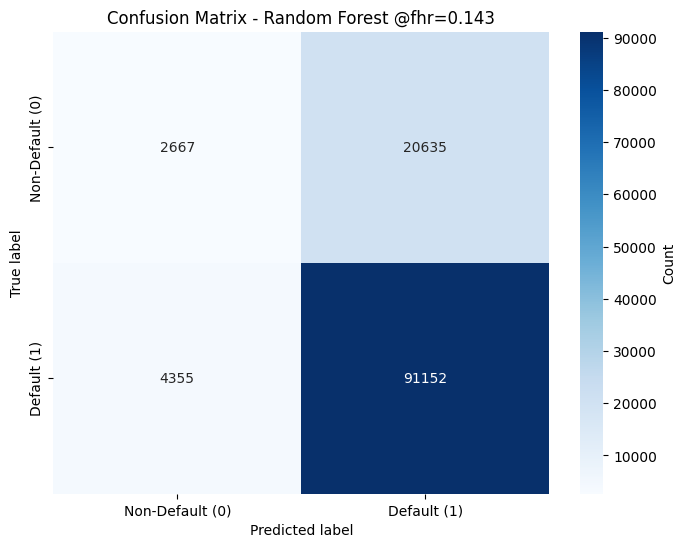

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# 定义类别标签（与你的业务场景对应，如这里的 Non-Default (0)、Default (1)）
labels = ["Non-Default (0)", "Default (1)"]

# 绘制热力图
plt.figure(figsize=(8, 6))
ax = sns.heatmap(
    RFcm, 
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

# 添加标题和轴标签
plt.title("Confusion Matrix - Random Forest @fhr=0.143")
plt.xlabel("Predicted label")
plt.ylabel("True label")

# 显示颜色条（与右侧数值刻度对应）
cbar = ax.collections[0].colorbar
cbar.set_label("Count")

plt.show()

ROC Curve

曲线下面积 (AUC): 0.6624


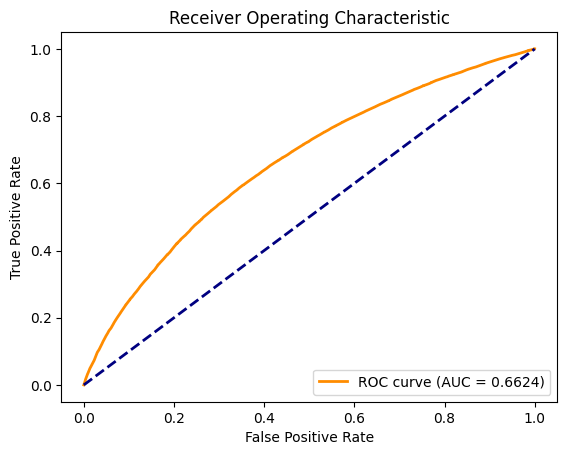


计算得到的 AUC 值为: 0.6624


In [10]:
# 获取预测的概率值 (第二列是预测为正例(1)的概率)
# ROC 曲线只需要正类的概率
y_proba = RFmodel.predict_proba(X_test)[:, 1]


import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# --- 增加 ROC 分析部分 ---
# 计算 ROC 曲线所需的 FPR, TPR
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
# 计算 AUC 值
roc_auc = auc(fpr, tpr)

# 打印 AUC 结果
print(f"曲线下面积 (AUC): {roc_auc:.4f}")

# 绘制 ROC 曲线图
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()
print(f"\n计算得到的 AUC 值为: {roc_auc:.4f}")

SHAP（SHapley Additive exPlanations）

In [16]:
! pip install lightgbm
! pip install shap


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: C:\Users\Linzixin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/547.8 kB ? eta -:--:--
   ---------------------------------------- 547.8/547.8 kB 11.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   -------------------------------------- - 2.6/2.7 MB 13.4 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 12.9 MB/s  0:00:00
   ---------------------------------------- 0.0/38.1 MB ? eta -:--:--
   -- ------------------------------------- 2.4/38.1 MB 12.6 MB/s eta 0:00:03
   ----- ---------------------------------- 5.0/38.1 MB 12.5 MB/s eta 0:00:03
   ------- -------------------------------- 7.6/38.1 MB 12.8 MB/s eta 0:00:03
   ---------- ----------------------------- 10.0/38.1 MB 12.4 MB/s eta 0:00:03
   ------------- -------------------------- 12.8/38.1 MB 12.9 MB/s eta 0:00:02
   ---------------- ----------------------- 16.0/38.1 MB 13.3 MB/s eta 0:00:02
   ---------


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: C:\Users\Linzixin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import lightgbm as lgb
import shap

# 初始化解释器
explainer = shap.TreeExplainer(RFmodel)
shap_values = explainer.shap_values(X_test)

# 汇总图（特征影响力）
shap.summary_plot(shap_values[1], X_test)

# 单个样本解释（例如第10个）
shap.force_plot(explainer.expected_value[1], shap_values[1][10,:], X_test.iloc[10,:])

C:\Users\Linzixin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
